# Car Price Prediction with Machine Learning
**CodeAlpha Data Science Internship – Task 3**

**Goal:** predict the *selling price* of a used car from features such as its original (showroom) price, age, kilometres driven, fuel type, seller type, transmission and number of previous owners.

**Workflow:** data audit → cleaning & feature engineering → EDA → model comparison with repeated cross-validation → held-out test evaluation → robustness checks → interpretation → saved model.

> Prices in this dataset are in **lakh INR** (1 lakh = 100,000 INR); the file does not state units, this follows the standard version of this dataset.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
import joblib

from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GroupKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
IMG = Path("images"); IMG.mkdir(exist_ok=True)
def save(n): plt.savefig(IMG / f"{n}.png", bbox_inches="tight", dpi=150)
SEED = 42
REF_YEAR = 2020   # Age = REF_YEAR - Year. Any constant works; it only shifts the intercept.

## 2. Load data

In [2]:
raw = pd.read_csv("data/car_data.csv")
print(raw.shape)
raw.head()

(301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Data audit
Before modelling I check types, missing values, duplicates and what the rows actually are.

In [3]:
df = raw.copy()
df.columns = df.columns.str.strip()
df["Car_Name"] = df["Car_Name"].str.strip()
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
display(df[df.duplicated(keep=False)])
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping exact duplicates:", df.shape)
df.describe().round(2)

Missing values: 0
Duplicate rows: 2


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


Shape after dropping exact duplicates: (299, 9)


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,299.00,299.00,299.00,299.00,299.00
mean,2013.62,4.59,7.54,36916.75,0.04
std,2.90,4.98,8.57,39015.17,0.25
min,2003.00,0.10,0.32,500.00,0.00
25%,2012.00,0.85,1.20,15000.00,0.00
50%,2014.00,3.51,6.10,32000.00,0.00
75%,2016.00,6.00,9.84,48883.50,0.00
max,2018.00,35.00,92.60,500000.00,3.00


### 3.1 Important finding: the file mixes cars and two-wheelers
`Car_Name` contains entries such as *Royal Enfield Classic 350*, *Bajaj Pulsar*, *Honda Activa*, *TVS Apache*. The task is **car** price prediction, so I separate them with an explicit list of the car models in the file.

Vehicle
Car            198
Two-wheeler    101
Name: count, dtype: int64


Selling_Price               Present_Price              
                    count median    max         count median    max
Vehicle                                                            
Car                   198   5.25  35.00           198   8.40  92.60
Two-wheeler           101   0.50   1.75           101   0.84   3.45

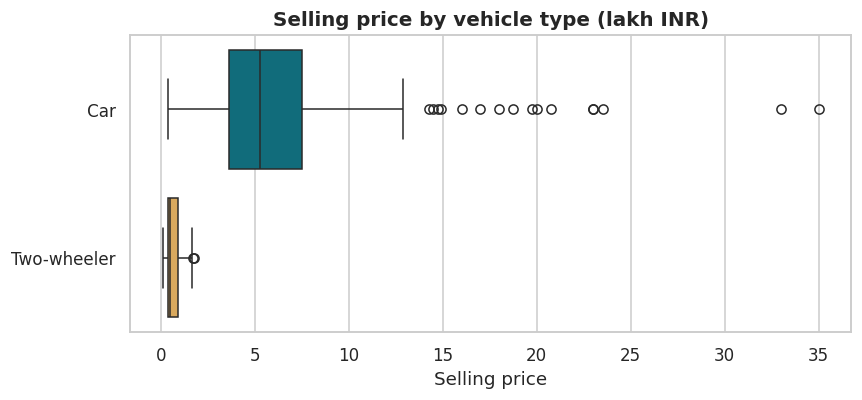

In [4]:
CAR_BRAND = {
 # Maruti Suzuki
 "800":"Maruti","alto 800":"Maruti","alto k10":"Maruti","baleno":"Maruti","ciaz":"Maruti","dzire":"Maruti",
 "ertiga":"Maruti","ignis":"Maruti","omni":"Maruti","ritz":"Maruti","s cross":"Maruti","swift":"Maruti",
 "sx4":"Maruti","vitara brezza":"Maruti","wagon r":"Maruti",
 # Hyundai
 "creta":"Hyundai","elantra":"Hyundai","eon":"Hyundai","grand i10":"Hyundai","i10":"Hyundai","i20":"Hyundai",
 "verna":"Hyundai","xcent":"Hyundai",
 # Honda
 "amaze":"Honda","brio":"Honda","city":"Honda","jazz":"Honda",
 # Toyota
 "camry":"Toyota","corolla":"Toyota","corolla altis":"Toyota","etios cross":"Toyota","etios g":"Toyota",
 "etios gd":"Toyota","etios liva":"Toyota","fortuner":"Toyota","innova":"Toyota","land cruiser":"Toyota",
}
df["Vehicle"] = np.where(df["Car_Name"].isin(CAR_BRAND), "Car", "Two-wheeler")
print(df["Vehicle"].value_counts())
display(df.groupby("Vehicle")[["Selling_Price", "Present_Price"]].agg(["count", "median", "max"]).round(2))
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=df, x="Selling_Price", y="Vehicle", ax=ax, palette=["#00798c", "#edae49"])
ax.set(title="Selling price by vehicle type (lakh INR)", xlabel="Selling price", ylabel="")
plt.tight_layout(); save("01_cars_vs_twowheelers"); plt.show()

Roughly a third of the file is two-wheelers priced about 10x lower. Mixing them would make the model look better than it is (an easy "cheap vs expensive" split inflates R²) while saying nothing about cars. **I model cars only** and report the all-vehicle number later only as a comparison.

## 4. Cleaning & feature engineering

In [5]:
cars = df[df["Vehicle"] == "Car"].copy().reset_index(drop=True)
cars["Brand"]   = cars["Car_Name"].map(CAR_BRAND)
cars["Age"]     = REF_YEAR - cars["Year"]
cars["LogPP"]   = np.log(cars["Present_Price"])        # new-car price, log scale
cars["LogKm"]   = np.log1p(cars["Driven_kms"])         # kilometres, log scale (right-skewed)
cars["Retained"] = cars["Selling_Price"] / cars["Present_Price"]   # share of new price kept (EDA only)

print("Cars used for modelling:", len(cars), "| models:", cars.Car_Name.nunique(), "| brands:", cars.Brand.nunique())
print("Rows where selling price > present price:", int((cars.Selling_Price > cars.Present_Price).sum()))
print("Fuel:", cars.Fuel_Type.value_counts().to_dict())
print("Owner:", cars.Owner.value_counts().to_dict())
cars[["Selling_Price","Present_Price","Driven_kms","Age","Owner"]].describe().round(2)

Cars used for modelling: 198 | models: 37 | brands: 4
Rows where selling price > present price: 0
Fuel: {'Petrol': 138, 'Diesel': 58, 'CNG': 2}
Owner: {0: 193, 1: 4, 3: 1}


,Selling_Price,Present_Price,Driven_kms,Age,Owner
count,198.00,198.00,198.00,198.00,198.00
mean,6.60,10.88,41403.92,6.43,0.04
std,5.04,8.81,27554.21,2.89,0.25
min,0.35,2.28,2071.00,2.00,0.00
25%,3.61,6.42,21964.25,4.25,0.00
50%,5.25,8.40,39742.50,6.00,0.00
75%,7.50,13.46,53621.25,8.00,0.00
max,35.00,92.60,197176.00,17.00,3.00


Notes: the `Land Cruiser` row (new price 92.6, sold at 35) is a genuine but extreme luxury car, so I **keep it** and later test how sensitive results are to it. `CNG` has only 2 rows and `Owner > 0` is rare, so those effects are weakly determined.

## 5. Exploratory data analysis

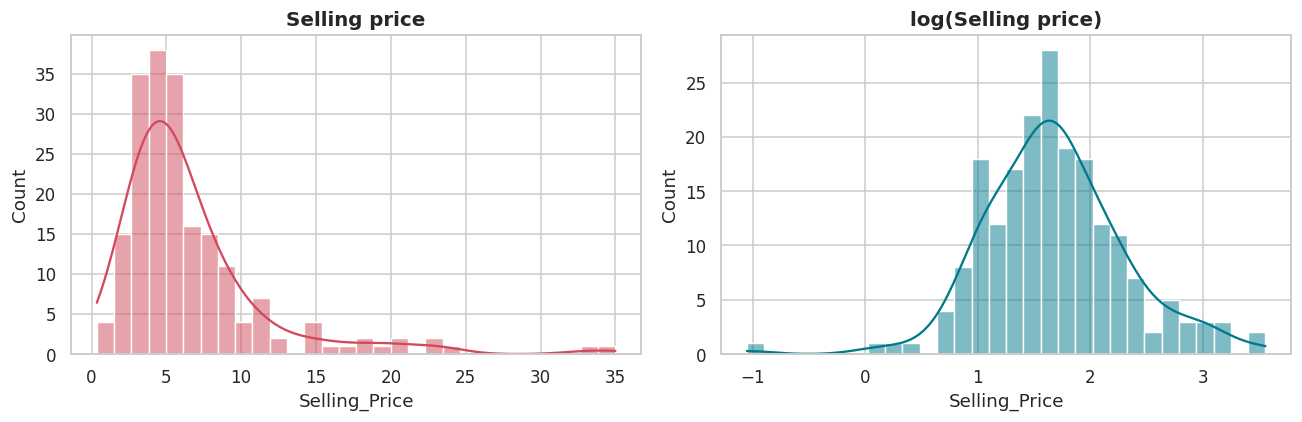

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(cars.Selling_Price, bins=30, kde=True, ax=ax[0], color="#d1495b"); ax[0].set_title("Selling price")
sns.histplot(np.log(cars.Selling_Price), bins=30, kde=True, ax=ax[1], color="#00798c"); ax[1].set_title("log(Selling price)")
plt.tight_layout(); save("02_price_distribution"); plt.show()

Price is strongly right-skewed; on the log scale it is much closer to symmetric. This is why the model predicts **log price**.

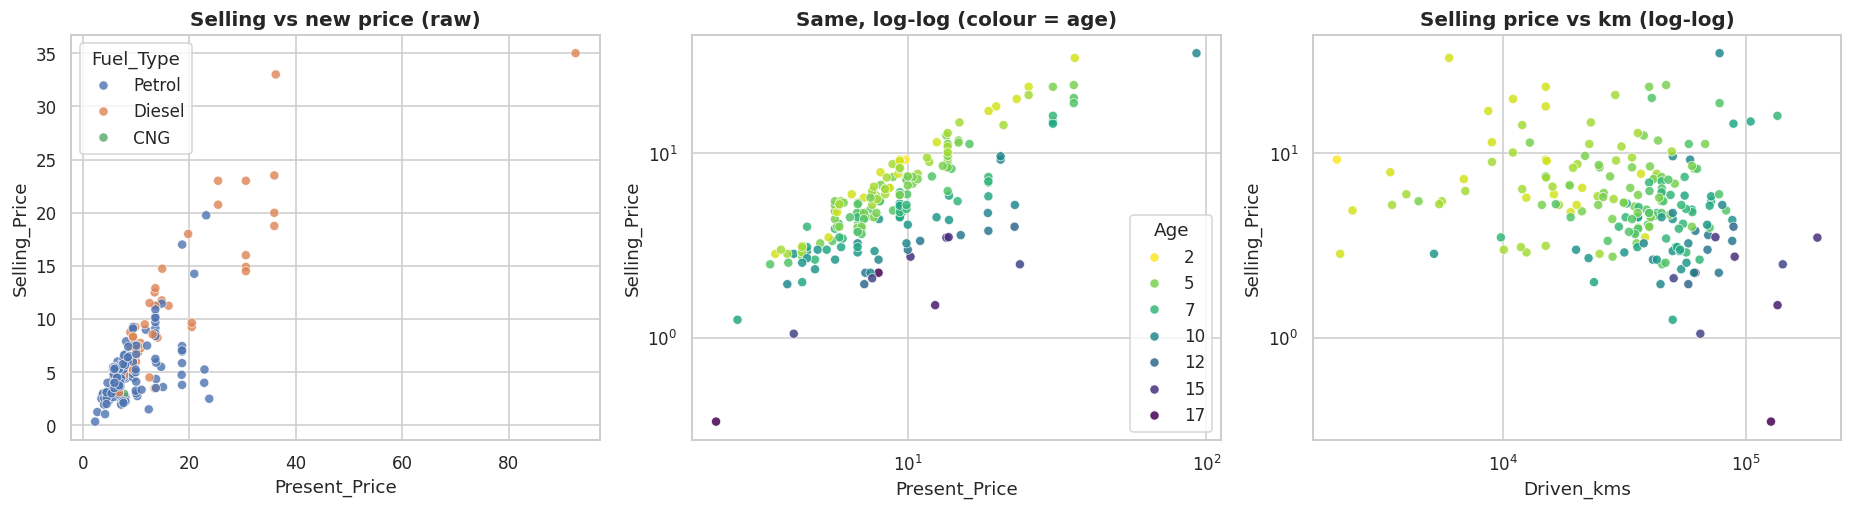

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.scatterplot(data=cars, x="Present_Price", y="Selling_Price", hue="Fuel_Type", ax=ax[0], alpha=.8)
ax[0].set_title("Selling vs new price (raw)")
sns.scatterplot(data=cars, x="Present_Price", y="Selling_Price", hue="Age", palette="viridis_r", ax=ax[1], alpha=.85)
ax[1].set(xscale="log", yscale="log", title="Same, log-log (colour = age)")
sns.scatterplot(data=cars, x="Driven_kms", y="Selling_Price", hue="Age", palette="viridis_r", ax=ax[2], alpha=.85, legend=False)
ax[2].set(xscale="log", yscale="log", title="Selling price vs km (log-log)")
plt.tight_layout(); save("03_price_relationships"); plt.show()

On log-log axes the relationship between new price and resale price becomes close to a straight line, which supports a multiplicative (percentage) model.

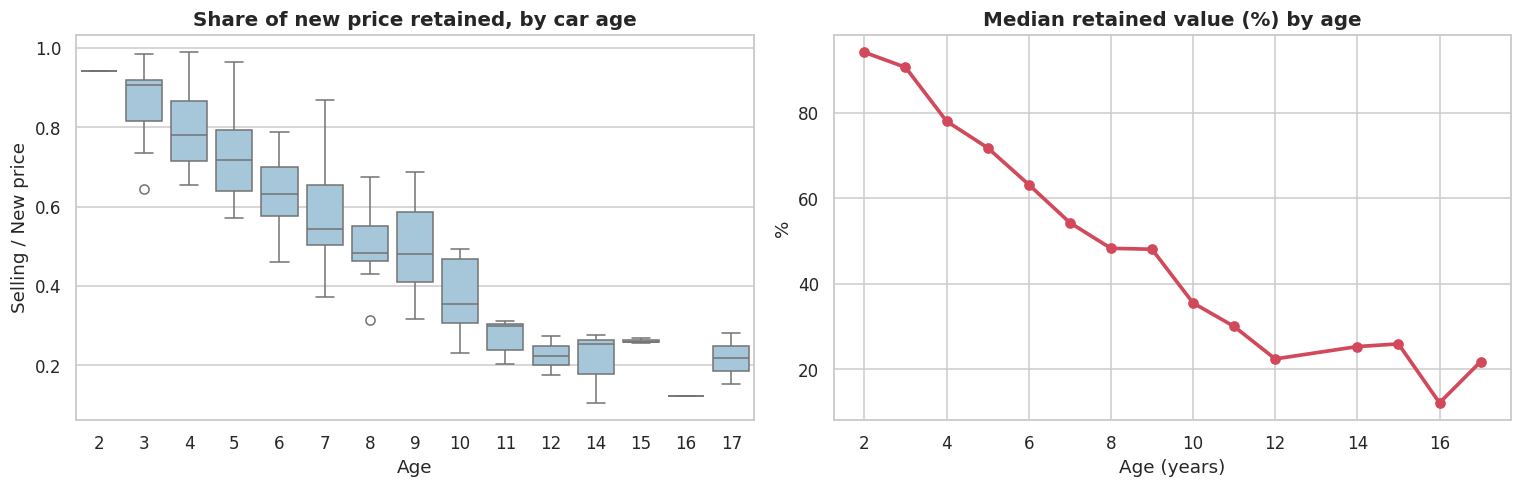

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
sns.boxplot(data=cars, x="Age", y="Retained", ax=ax[0], color="#9ecae1")
ax[0].set(title="Share of new price retained, by car age", ylabel="Selling / New price")
med = cars.groupby("Age").Retained.median()
ax[1].plot(med.index, med.values * 100, marker="o", color="#d1495b", lw=2.4)
ax[1].set(title="Median retained value (%) by age", xlabel="Age (years)", ylabel="%")
plt.tight_layout(); save("04_depreciation"); plt.show()

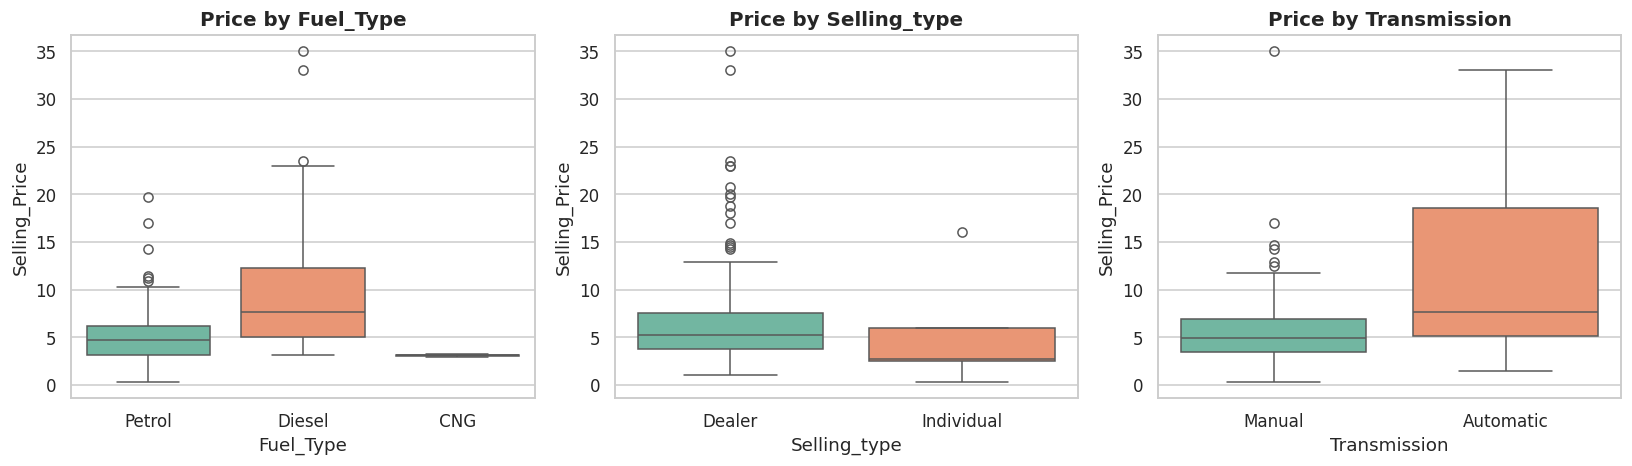

,count,median
Brand,,
Honda,50,5.70
Hyundai,50,5.03
Maruti,49,4.60
Toyota,49,5.85


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a, col in zip(ax, ["Fuel_Type", "Selling_type", "Transmission"]):
    sns.boxplot(data=cars, x=col, y="Selling_Price", ax=a, palette="Set2"); a.set_title(f"Price by {col}")
plt.tight_layout(); save("05_categorical"); plt.show()
cars.groupby("Brand").Selling_Price.agg(["count", "median"]).round(2)

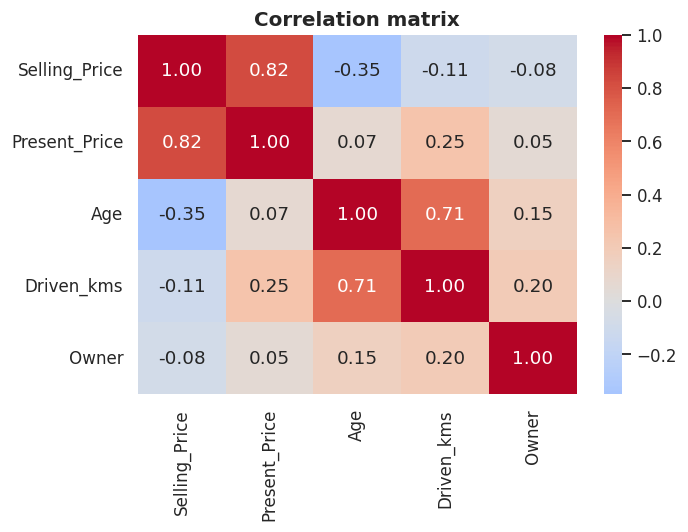

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cars[["Selling_Price", "Present_Price", "Age", "Driven_kms", "Owner"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix"); plt.tight_layout(); save("06_correlation"); plt.show()

New price is by far the strongest single driver; age is the next most important and is negative. Note that new price and age are partly entangled (older cars were cheaper when new), so effects should be read as *conditional*.

## 6. Modelling setup
* **Target:** `log(Selling_Price)`; predictions are converted back to lakh INR.
* **Features:** `log(Present_Price)`, `Age`, `log(1 + Driven_kms)`, `Owner`, `Fuel_Type`, `Selling_type`, `Transmission`.
* **Preprocessing inside a Pipeline** (scaling + one-hot), so nothing leaks from validation folds.
* **Evaluation:** 80/20 hold-out test split (as the task suggests) **plus** 5-fold x 10-repeat cross-validation, because with ~200 rows a single split is noisy.
* **Metrics:** R², MAE, RMSE (lakh INR) and median absolute percentage error (MdAPE).

In [11]:
NUM = ["LogPP", "Age", "LogKm", "Owner"]
CAT = ["Fuel_Type", "Selling_type", "Transmission"]
X, y = cars[NUM + CAT], cars["Selling_Price"]

def build(model, num=NUM, cat=CAT, log_target=True, scale=True):
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat)])
    pipe = Pipeline([("pre", pre), ("model", model)])
    return TransformedTargetRegressor(pipe, func=np.log, inverse_func=np.exp) if log_target else pipe

def mdape(est, X, y):                       # scorer: median absolute % error (as a negative number)
    return -np.median(np.abs(est.predict(X) - y) / y) * 100

SCORING = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "mdape": mdape}
CV = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)

def cv_table(models, X, y, cv=CV):
    rows = {}
    for name, est in models.items():
        s = cross_validate(est, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
        rows[name] = {"R2": s["test_r2"].mean(), "R2 std": s["test_r2"].std(),
                      "MAE": -s["test_mae"].mean(), "RMSE": -s["test_rmse"].mean(), "MdAPE %": -s["test_mdape"].mean()}
    return pd.DataFrame(rows).T.round(3)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (158, 7) Test: (40, 7)


## 7. Model comparison (repeated cross-validation)

In [12]:
RAW_NUM = ["Present_Price", "Age", "Driven_kms", "Owner"]
models = {
  "Baseline: Linear (raw price, raw features)": build(LinearRegression(), num=RAW_NUM, log_target=False),
  "Linear (log price, log features)":           build(LinearRegression()),
  "Ridge (alpha=1)":                            build(Ridge(alpha=1.0)),
  "Random Forest":                              build(RandomForestRegressor(300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
  "Gradient Boosting":                          build(GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=SEED)),
}
# the baseline needs the raw columns, the others the log columns -> evaluate with the right X
Xraw = cars[RAW_NUM + CAT]
res = pd.concat([
    cv_table({k: v for k, v in models.items() if k.startswith("Baseline")}, Xraw, y),
    cv_table({k: v for k, v in models.items() if not k.startswith("Baseline")}, X, y)])
res

,R2,R2 std,MAE,RMSE,MdAPE %
"Baseline: Linear (raw price, raw features)",0.816,0.077,1.353,2.005,16.958
"Linear (log price, log features)",0.941,0.025,0.772,1.128,11.516
Ridge (alpha=1),0.941,0.025,0.774,1.133,11.572
Random Forest,0.843,0.134,0.951,1.876,9.762
Gradient Boosting,0.866,0.122,0.888,1.715,10.218


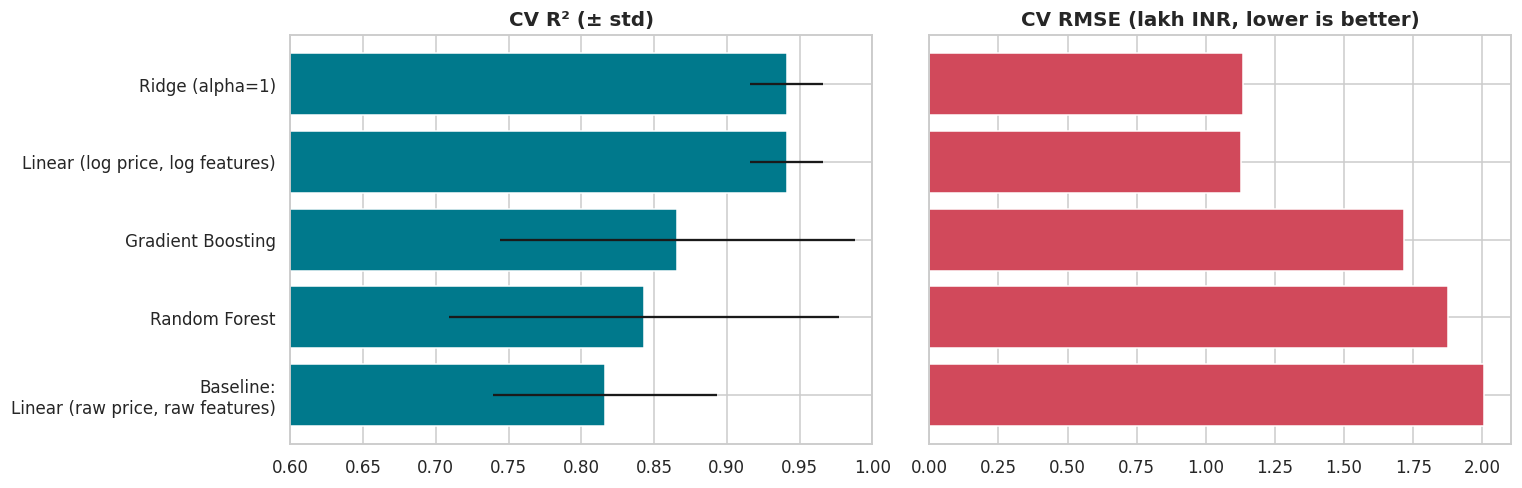

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
order = res.sort_values("R2").index
ax[0].barh(order, res.loc[order, "R2"], xerr=res.loc[order, "R2 std"], color="#00798c"); ax[0].set(title="CV R² (± std)", xlim=(0.6, 1))
ax[1].barh(order, res.loc[order, "RMSE"], color="#d1495b"); ax[1].set(title="CV RMSE (lakh INR, lower is better)")
for a in ax: a.set_yticklabels([o.replace(": ", ":\n") for o in order]) if a is ax[0] else a.set_yticklabels([])
plt.tight_layout(); save("07_model_comparison"); plt.show()

**Reading the table**
- The baseline (plain linear regression on raw values) reaches R² = 0.82 with a typical error (RMSE) of ~2.0 lakh. Modelling **log price from log new-price, age and log km** lifts R² to **0.94** and cuts RMSE to ~1.1 lakh, with much lower fold-to-fold variation (std 0.025).
- Random Forest and Gradient Boosting have a *lower median % error* (about 10%) but a **worse RMSE and R², with high variance across folds**. They make a few large mistakes, mostly on the most expensive car (see 9b).
- Ridge adds nothing over plain linear regression here: with 7 features and ~200 rows there is little overfitting to regularise.
- Why logs? Resale value behaves multiplicatively (a car loses a *percentage* of its value per year). Trees also cannot predict beyond the price range they saw in training, while a log-log linear model extrapolates sensibly. A log target combined with *raw* features is risky (it extrapolates exponentially), so both sides are logged.

### 7.1 Does brand ("goodwill") add anything?
The task mentions brand goodwill. The file only has model names, so I mapped each model to its brand (Maruti, Hyundai, Honda, Toyota) and tested adding it.

In [14]:
Xb = cars[NUM + CAT + ["Brand"]]
brand = cv_table({"Linear + Brand": build(LinearRegression(), cat=CAT + ["Brand"])}, Xb, y)
pd.concat([res.loc[["Linear (log price, log features)"]], brand])

,R2,R2 std,MAE,RMSE,MdAPE %
"Linear (log price, log features)",0.941,0.025,0.772,1.128,11.516
Linear + Brand,0.944,0.023,0.754,1.100,10.349


Adding brand changes R² from 0.941 to 0.944 and MdAPE from 11.5% to 10.3%, well inside the fold-to-fold noise (R² std ≈ 0.025). With only four brands and new price already capturing the price tier, **brand goodwill is not a reliably useful extra feature in this data**, so I leave it out of the final model to keep it simpler.

### 7.2 Tuning the strongest non-linear model

In [15]:
grid = {"regressor__model__n_estimators": [150, 300, 500],
        "regressor__model__learning_rate": [0.03, 0.05, 0.1],
        "regressor__model__max_depth": [2, 3]}
gs = GridSearchCV(build(GradientBoostingRegressor(subsample=0.8, random_state=SEED)), grid,
                  cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_mean_absolute_error", n_jobs=-1)
gs.fit(X_train, y_train)               # tuned on the TRAIN split only
print("Best params:", gs.best_params_)

Best params: {'regressor__model__learning_rate': 0.03, 'regressor__model__max_depth': 2, 'regressor__model__n_estimators': 500}


## 8. Hold-out test evaluation

In [16]:
def metrics(y_true, pred):
    return {"R2": r2_score(y_true, pred), "MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "MdAPE %": np.median(np.abs(pred - y_true) / y_true) * 100}

final_candidates = {
  "Linear (log-log)": build(LinearRegression()),
  "Ridge":            build(Ridge(alpha=1.0)),
  "Random Forest":    build(RandomForestRegressor(300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
  "Gradient Boosting (tuned)": gs.best_estimator_,
}
test_rows = {}
for n, m in final_candidates.items():
    m.fit(X_train, y_train); test_rows[n] = metrics(y_test, m.predict(X_test))
# baseline on raw features for reference
base = build(LinearRegression(), num=RAW_NUM, log_target=False).fit(Xraw.loc[X_train.index], y_train)
test_rows = {"Baseline (raw linear)": metrics(y_test, base.predict(Xraw.loc[X_test.index])), **test_rows}
pd.DataFrame(test_rows).T.round(3)

,R2,MAE,RMSE,MdAPE %
Baseline (raw linear),0.797,1.422,2.616,17.158
Linear (log-log),0.911,0.994,1.735,16.091
Ridge,0.907,1.004,1.769,15.884
Random Forest,0.613,1.260,3.616,8.848
Gradient Boosting (tuned),0.573,1.350,3.797,12.124


On the 40-car hold-out set the log-log linear model scores **R² ≈ 0.91, MAE ≈ 1.0 lakh, RMSE ≈ 1.7 lakh**, clearly better than the raw baseline (R² ≈ 0.80, RMSE ≈ 2.6). The tree models score much lower here (R² ≈ 0.57–0.61).

The reason is specific: this particular test split contains the **Land Cruiser** (new price 92.6), while the most expensive car in the training part costs 36.2. Tree models cannot predict beyond what they saw, so they badly under-predict it, whereas the log-log linear model extrapolates. The hold-out number is therefore sensitive to one car, which is why I rely on repeated cross-validation as the main evidence and treat this table as a secondary check.

## 9. Robustness checks

**(a) Unseen car models.** Random splits let the same model (e.g. several *City* rows) appear in train and test. A stricter test holds out **whole car models** (`GroupKFold`), which is closer to predicting a car the model has never seen.

In [17]:
gk = GroupKFold(n_splits=5)
g_rows = {}
for n, m in {"Linear (log-log)": build(LinearRegression()), "Ridge": build(Ridge(1.0)),
             "Random Forest": build(RandomForestRegressor(300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
             "Gradient Boosting (tuned)": gs.best_estimator_}.items():
    p = cross_val_predict(m, X, y, cv=gk, groups=cars["Car_Name"])
    g_rows[n] = metrics(y, p)
pd.DataFrame(g_rows).T.round(3)

,R2,MAE,RMSE,MdAPE %
Linear (log-log),0.909,0.955,1.518,12.977
Ridge,0.913,0.945,1.488,12.925
Random Forest,0.647,1.466,2.989,15.158
Gradient Boosting (tuned),0.687,1.396,2.815,14.799


Even when whole car models are held out, the log-log linear model keeps **R² ≈ 0.91** (MAE ≈ 0.95 lakh), while the tree models drop to **≈ 0.65–0.69**. The linear model generalises better to cars it has not seen because it learns the *price-to-resale relationship* rather than memorising model-specific price levels.

**(b) Sensitivity to the Land Cruiser outlier** (new price 92.6, 2.5x the next most expensive car).

In [18]:
nolc = cars[cars.Car_Name != "land cruiser"]
cv_table({"Linear (log-log)": build(LinearRegression()),
          "Gradient Boosting": models["Gradient Boosting"],
          "Random Forest": models["Random Forest"]}, nolc[NUM + CAT], nolc["Selling_Price"])

,R2,R2 std,MAE,RMSE,MdAPE %
Linear (log-log),0.944,0.026,0.742,0.988,11.471
Gradient Boosting,0.918,0.034,0.810,1.246,10.545
Random Forest,0.887,0.100,0.863,1.424,9.651


**(c) What if two-wheelers were kept in?** (for comparison only; not a fair car benchmark)

In [19]:
al = df.copy()
al["Age"] = REF_YEAR - al["Year"]; al["LogPP"] = np.log(al["Present_Price"]); al["LogKm"] = np.log1p(al["Driven_kms"])
al["IsCar"] = (al["Vehicle"] == "Car").astype(int)
cv_table({"Linear (all vehicles)": build(LinearRegression(), num=NUM + ["IsCar"]),
          "Gradient Boosting (all vehicles)": build(GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=SEED), num=NUM + ["IsCar"])},
         al[NUM + ["IsCar"] + CAT], al["Selling_Price"])

,R2,R2 std,MAE,RMSE,MdAPE %
Linear (all vehicles),0.970,0.012,0.525,0.811,11.812
Gradient Boosting (all vehicles),0.901,0.097,0.629,1.466,10.794


- **Without the Land Cruiser** all models improve (linear R² 0.944, boosting 0.918, forest 0.887) and the gap between linear and trees narrows. Linear is still best on R² and RMSE, boosting/forest are slightly better on median % error. So the conclusion does not hinge on that single car, but tree models are clearly more affected by it.
- **Keeping two-wheelers in** gives R² ≈ 0.97 for the linear model, which looks better but is misleading: much of the gain is just separating cheap bikes from cars. That is why the car-only 0.94 is the honest benchmark for this task.

## 10. Final model diagnostics

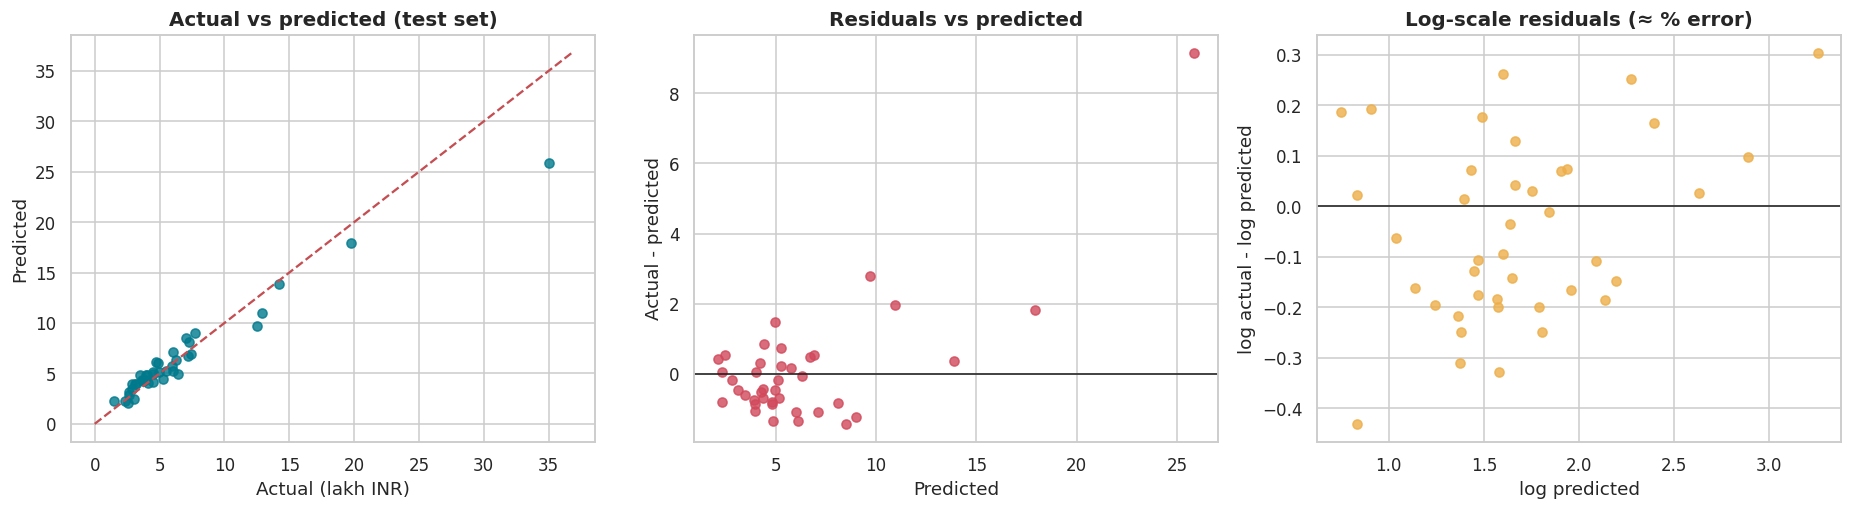

In [20]:
FINAL_NAME = "Linear (log-log)"
final = build(LinearRegression()).fit(X_train, y_train)
pred = final.predict(X_test)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
lim = [0, max(y_test.max(), pred.max()) * 1.05]
ax[0].scatter(y_test, pred, alpha=.8, color="#00798c"); ax[0].plot(lim, lim, "r--")
ax[0].set(title="Actual vs predicted (test set)", xlabel="Actual (lakh INR)", ylabel="Predicted")
ax[1].scatter(pred, y_test - pred, alpha=.8, color="#d1495b"); ax[1].axhline(0, color="k", lw=1)
ax[1].set(title="Residuals vs predicted", xlabel="Predicted", ylabel="Actual - predicted")
ax[2].scatter(np.log(pred), np.log(y_test) - np.log(pred), alpha=.8, color="#edae49"); ax[2].axhline(0, color="k", lw=1)
ax[2].set(title="Log-scale residuals (≈ % error)", xlabel="log predicted", ylabel="log actual - log predicted")
plt.tight_layout(); save("08_diagnostics"); plt.show()

,n,MAE,MdAPE
band,,,
<3,34,0.50,17.19
3-6,92,0.63,13.34
6-10,45,0.78,9.06
>10,27,1.61,10.24


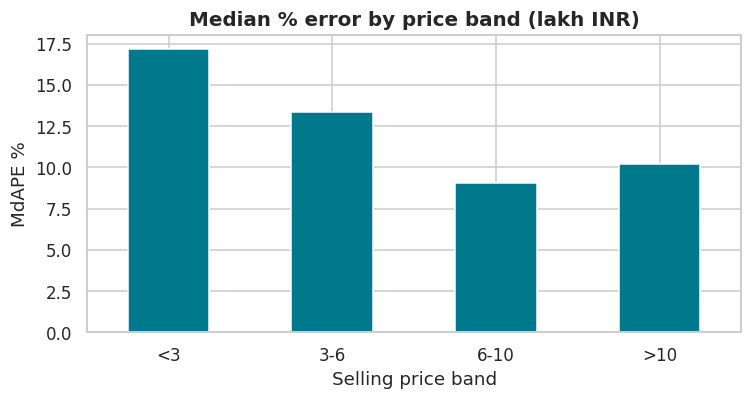

,Car_Name,Year,Present_Price,Driven_kms,Fuel_Type,Selling_Price,Predicted,AbsErr
85,land cruiser,2010,92.60,78000,Diesel,35.00,25.86,9.14
5,vitara brezza,2018,9.83,2071,Diesel,9.25,12.94,3.69
82,innova,2015,13.46,38000,Diesel,12.50,9.72,2.78
50,fortuner,2015,30.61,40000,Diesel,23.00,20.23,2.77
79,corolla altis,2016,14.89,23000,Diesel,14.73,12.41,2.32
84,camry,2006,23.73,142000,Petrol,2.50,4.82,2.32


In [21]:
# Error by price band, using out-of-fold predictions over ALL cars (more points than the 40-row test set)
oof = cross_val_predict(build(LinearRegression()), X, y, cv=KFold(5, shuffle=True, random_state=SEED))
band = pd.cut(y, [0, 3, 6, 10, 100], labels=["<3", "3-6", "6-10", ">10"])
e = pd.DataFrame({"band": band, "abs_err": np.abs(oof - y), "pct_err": np.abs(oof - y) / y * 100})
tab = e.groupby("band", observed=True).agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), MdAPE=("pct_err", "median")).round(2)
display(tab)
fig, ax = plt.subplots(figsize=(7, 3.8))
tab["MdAPE"].plot.bar(ax=ax, color="#00798c", rot=0); ax.set(title="Median % error by price band (lakh INR)", xlabel="Selling price band", ylabel="MdAPE %")
plt.tight_layout(); save("09_error_by_band"); plt.show()

worst = cars.assign(Predicted=oof.round(2), AbsErr=np.abs(oof - y).round(2)).nlargest(6, "AbsErr")
worst[["Car_Name", "Year", "Present_Price", "Driven_kms", "Fuel_Type", "Selling_Price", "Predicted", "AbsErr"]]

- Absolute errors grow with price (MAE ≈ 0.5 lakh under 3 lakh vs ≈ 1.6 lakh above 10 lakh), but **percentage errors are lowest for mid-priced cars** (median ≈ 9% for 6–10 lakh) and highest for the cheapest cars (≈ 17% under 3 lakh), where a small absolute gap is a large share of a small price.
- The largest single miss is the **Land Cruiser** (predicted ≈ 25.9 vs actual 35.0 lakh), a luxury outlier with no similar car in the data. Other big misses are diesel SUVs/MPVs (Vitara Brezza, Innova, Fortuner).

## 11. Interpretation

In [22]:
# Unscaled linear model on log price so coefficients have a direct meaning
interp = TransformedTargetRegressor(
    Pipeline([("pre", ColumnTransformer([("num", "passthrough", NUM),
                                         ("cat", OneHotEncoder(drop="first"), CAT)])),
              ("model", LinearRegression())]), func=np.log, inverse_func=np.exp).fit(X, y)
names = interp.regressor_.named_steps["pre"].get_feature_names_out()
coef = pd.Series(interp.regressor_.named_steps["model"].coef_, index=names)

out = pd.DataFrame({"coef (log scale)": coef.round(3)})
out["effect on price"] = ""
out.loc["num__LogPP", "effect on price"] = f"+1% new price -> {coef['num__LogPP']:+.2f}% resale price"
out.loc["num__Age", "effect on price"]   = f"each extra year -> {(np.exp(coef['num__Age'])-1)*100:+.1f}%"
out.loc["num__LogKm", "effect on price"] = f"doubling km driven -> {(2**coef['num__LogKm']-1)*100:+.1f}%"
out.loc["num__Owner", "effect on price"] = f"each previous owner -> {(np.exp(coef['num__Owner'])-1)*100:+.1f}%"
for k in coef.index:
    if k.startswith("cat__"):
        out.loc[k, "effect on price"] = f"vs reference level -> {(np.exp(coef[k])-1)*100:+.1f}%"
out

,coef (log scale),effect on price
num__LogPP,0.834,+1% new price -> +0.83% resale price
num__Age,-0.106,each extra year -> -10.1%
num__LogKm,-0.070,doubling km driven -> -4.7%
num__Owner,-0.140,each previous owner -> -13.1%
cat__Fuel_Type_Diesel,0.294,vs reference level -> +34.2%
cat__Fuel_Type_Petrol,0.110,vs reference level -> +11.7%
cat__Selling_type_Individual,-0.033,vs reference level -> -3.3%
cat__Transmission_Manual,-0.042,vs reference level -> -4.1%


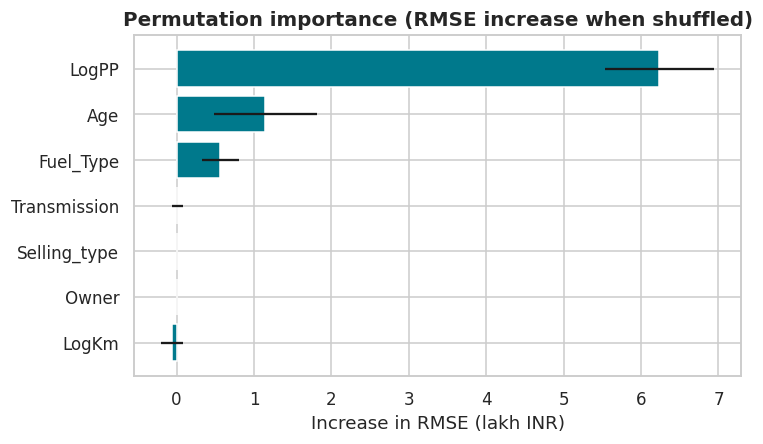

In [23]:
pi = permutation_importance(final, X_test, y_test, n_repeats=30, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.index], color="#00798c")
ax.set(title="Permutation importance (RMSE increase when shuffled)", xlabel="Increase in RMSE (lakh INR)")
plt.tight_layout(); save("10_importance"); plt.show()

**Reading the coefficients** (conditional on the other features):
- **New price** is the dominant driver: +1% in the original price is associated with about +0.83% in resale price.
- **Age:** each additional year is associated with about **−10%** in price.
- **Kilometres:** doubling the distance driven is associated with about −5%, a much smaller effect than age.
- **Fuel:** diesel cars sell for roughly 20% more than petrol cars of similar price, age and mileage (from the coefficients: +34% vs +12% relative to CNG). CNG has only 2 rows, so treat the CNG reference level as unreliable.
- **Owner, seller type and transmission** show small effects. Only 5 cars have more than one previous owner, so the −13% per owner estimate is weakly determined, and the seller-type/transmission effects are small relative to the noise.

The permutation importance agrees: **new price ≫ age > fuel type**, with the remaining features adding little. (New price looks especially large here because the Land Cruiser is in this 40-row test set.)

## 12. Save the model and predict for a new car

In [24]:
# Refit on all cars for the saved model; keep out-of-fold log errors to give an honest price range
final_all = build(LinearRegression()).fit(X, y)
joblib.dump(final_all, "car_price_model.joblib")
log_err = np.log(y) - np.log(oof)
q05, q95 = np.quantile(log_err, [0.05, 0.95])

def predict_price(present_price, year, driven_kms, fuel, seller, transmission, owner=0):
    row = pd.DataFrame([{"LogPP": np.log(present_price), "Age": REF_YEAR - year, "LogKm": np.log1p(driven_kms),
                         "Owner": owner, "Fuel_Type": fuel, "Selling_type": seller, "Transmission": transmission}])
    p = float(final_all.predict(row)[0])
    return round(p, 2), (round(p * np.exp(q05), 2), round(p * np.exp(q95), 2))

p, (lo, hi) = predict_price(present_price=9.5, year=2015, driven_kms=45000, fuel="Petrol", seller="Dealer", transmission="Manual")
print(f"Estimated selling price: {p} lakh INR  (90% range: {lo} - {hi})")
p, (lo, hi) = predict_price(present_price=20, year=2016, driven_kms=60000, fuel="Diesel", seller="Dealer", transmission="Automatic")
print(f"Estimated selling price: {p} lakh INR  (90% range: {lo} - {hi})")

Estimated selling price: 6.01 lakh INR  (90% range: 4.47 - 7.74)
Estimated selling price: 15.27 lakh INR  (90% range: 11.36 - 19.65)


## 13. Conclusions

**Result.** The final model is a **linear regression on log price** using log new-price, age, log km, owner count, fuel type, seller type and transmission.
- Repeated 5x10 cross-validation: **R² 0.94, MAE ≈ 0.77 lakh, RMSE ≈ 1.1 lakh, median error ≈ 11.5%**.
- Hold-out test: R² ≈ 0.91. Unseen-model check: R² ≈ 0.91.

**Why this model.** It has the best R²/RMSE, the lowest variance across folds, the best generalisation to unseen models and extrapolates to expensive cars, and it is easy to explain. Gradient boosting/forest are competitive on median % error but less stable.

**Business takeaways**
1. Resale value is driven mainly by the car's original price and age (about −10% per year), with fuel type next; kilometres matter less once age is known.
2. Diesel cars hold their value better than comparable petrol cars.
3. Predictions are best for mid-priced cars; expect larger percentage errors for very cheap cars and for rare luxury cars.

**Limitations**
- Small dataset (198 cars, 37 models, 4 brands); results are noisy for rare cases (CNG, multiple owners, luxury).
- Only one car above 40 lakh new price, so very expensive cars are poorly constrained.
- The data covers cars from 2003–2018 and prices from that era; predictions do not reflect today's market and would need retraining on fresh data.
- Two-wheelers were excluded; Condition, city, variant, accident history and similar real drivers of price are not in the data.
- Coefficients describe associations, not causes.